In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

make_blobs helps generate clusters

In [ ]:
x,y_true=make_blobs(n_samples=500,centers=3,cluster_std=0.6 ,random_state=42)

In [ ]:
x

array([[-6.1900632 , -7.30201545],
       [ 3.02174685,  1.94059276],
       [ 5.9537606 ,  1.48819071],
       [-2.74446251,  8.13617716],
       [ 5.36060719,  1.72832446],
       [ 5.13808033,  1.45951939],
       [-5.34357647, -6.93774553],
       [ 4.80215293,  1.94302682],
       [ 3.99930658,  1.88774199],
       [-7.25451834, -6.86445496],
       [ 4.25193511,  1.32424088],
       [-1.81404028,  8.52187674],
       [-1.2293776 ,  7.84303345],
       [-2.16666332,  9.69562551],
       [ 4.81374375,  3.21841016],
       [ 5.27493353,  0.91792599],
       [-2.5524037 ,  9.61640587],
       [-7.5532604 , -6.65066375],
       [-6.8302568 , -6.24082137],
       [-3.17299861,  8.29656215],
       [ 3.80073829,  2.31095123],
       [-2.38387947,  7.83848405],
       [ 4.98581301,  2.15991978],
       [-5.94031277, -6.91955975],
       [-7.14748736, -6.7636556 ],
       [ 4.87655012,  1.720579  ],
       [ 4.48689251,  2.87556548],
       [-6.4081471 , -6.62483506],
       [-6.71939703,

In [ ]:
df=pd.DataFrame(x,columns=['Feature1','Feature2'])
df


,Feature1,Feature2
0,-6.190063,-7.302015
1,3.021747,1.940593
2,5.953761,1.488191
3,-2.744463,8.136177
4,5.360607,1.728324
...,...,...
495,-6.040014,-6.325329
496,-2.555459,9.218977
497,4.438408,2.974583
498,-7.193261,-6.250704


In [ ]:
scaler=StandardScaler()
x_scaled=scaler.fit_transform(df)
x_scaled.shape

(500, 2)

IMPLEMENTING ELBOW METHOD

In [ ]:
inertia=[] #this is WCSS
K_range=range(1,11)
for k in K_range:
  kmeans=KMeans(n_clusters=k,random_state=42)
  kmeans.fit(x_scaled)
  inertia.append(kmeans.inertia_)


inertia


[1000.0000000000006,
 297.8954141051723,
 11.575484723104985,
 9.752067977356848,
 8.257175272446279,
 6.917577320416797,
 6.334755391595288,
 5.704177177901426,
 5.060234133532074,
 4.7623618981303935]

Text(0, 0.5, 'Inertia')

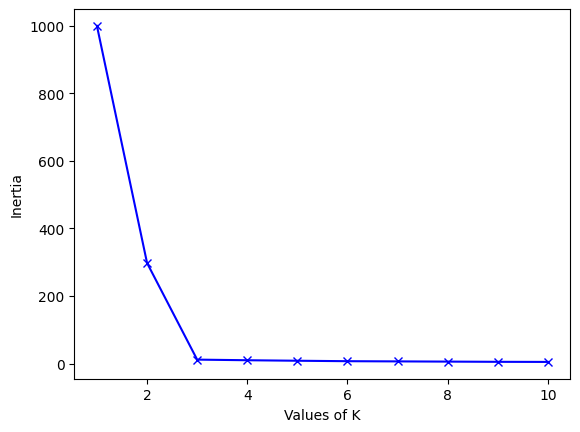

In [ ]:
plt.plot(K_range,inertia,'bx-')
plt.xlabel('Values of K')
plt.ylabel('Inertia')


THIS GIVES EBST K AS 3

In [ ]:
kmeans_final=KMeans(n_clusters=3,random_state=42)

In [ ]:
cluster_labels=kmeans_final.fit_predict(x_scaled)
cluster_labels.shape

(500,)

WE WILL MAKE. SCATTER PLOT NOW

In [ ]:
df['cluster']=cluster_labels


<Axes: xlabel='Feature1', ylabel='Feature2'>

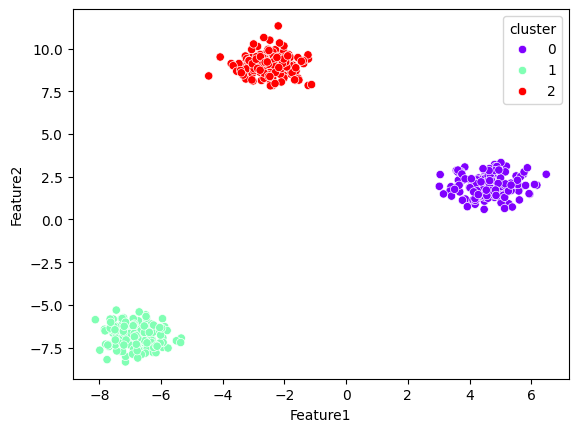

In [ ]:
sns.scatterplot(data=df,x='Feature1',y='Feature2',hue='cluster',palette='rainbow')


IMPLEMENTING DB SCAN NOW


In [ ]:
from sklearn.datasets import make_moons
x,y_true=make_moons(n_samples=500,noise=0.05,random_state=42)

In [ ]:
from sklearn.cluster import KMeans , DBSCAN
df=pd.DataFrame(x,columns=['Feature1','Feature2'])
df


,Feature1,Feature2
0,0.830586,-0.447733
1,0.701678,0.816918
2,1.022080,-0.492571
3,-0.316765,0.953438
4,0.293226,1.057185
...,...,...
495,0.239754,0.985462
496,0.072145,0.184834
497,0.590273,-0.365577
498,1.619465,-0.283658


<Axes: xlabel='Feature1', ylabel='Feature2'>

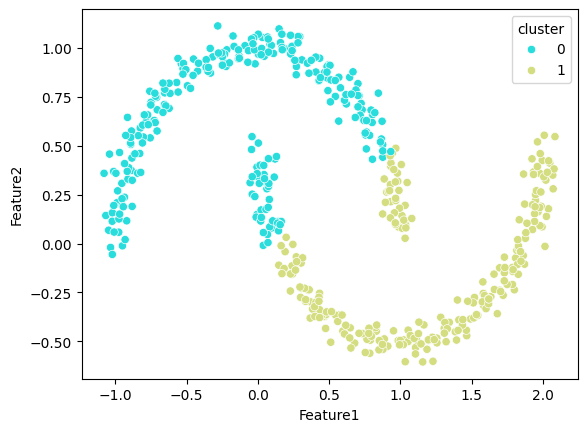

In [ ]:
scaler=StandardScaler()
x_scaled=scaler.fit_transform(df)
kmeans=KMeans(n_clusters=2,random_state=42)
kmeans_labels=kmeans.fit_predict(x_scaled)
df['cluster']=kmeans_labels
sns.scatterplot(data=df,x='Feature1',y='Feature2',hue='cluster',palette='rainbow')

In [ ]:
dbscan=DBSCAN(eps=0.3,min_samples=5)

<Axes: xlabel='Feature1', ylabel='Feature2'>

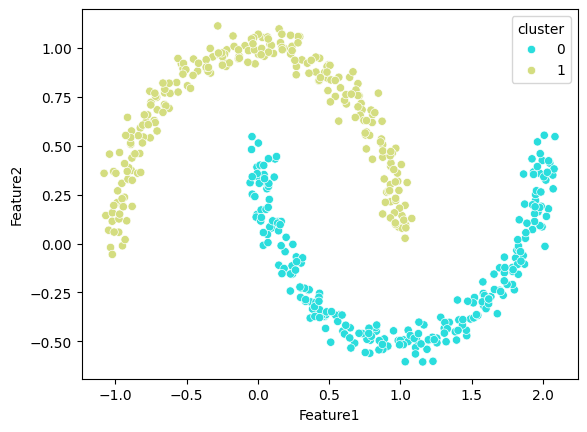

In [ ]:
dbscan_labels=dbscan.fit_predict(x_scaled)
df['cluster']=dbscan_labels
sns.scatterplot(data=df,x='Feature1',y='Feature2',hue='cluster',palette='rainbow')
#

In dimensioanl redn, there will always will some info. loss

In [ ]:
from sklearn.decomposition import PCA
x,y=make_blobs(n_samples=500,centers=3,cluster_std=1.5 ,random_state=42)

In [ ]:
scaler=StandardScaler()
x_scaled=scaler.fit_transform(x)
x_scaled.shape

(500, 2)

In [ ]:
pca=PCA(n_components=2)
x_pca=pca.fit_transform(x_scaled)
x_pca

array([[-1.52014328e+00, -4.88015288e-01],
       [ 3.58714758e-01, -2.61226335e-01],
       [ 1.29050939e+00, -1.43537307e+00],
       [ 3.56276564e-01,  7.97032173e-01],
       [ 1.14181080e+00, -1.15803466e+00],
       [ 9.89895458e-01, -1.15011838e+00],
       [-1.11857566e+00, -6.94443254e-01],
       [ 9.98761881e-01, -8.99969534e-01],
       [ 6.95628546e-01, -6.26452319e-01],
       [-1.78521908e+00,  1.14619783e-02],
       [ 6.35420761e-01, -8.68112480e-01],
       [ 7.93727787e-01,  5.66200488e-01],
       [ 8.21868597e-01,  1.74402846e-01],
       [ 9.81479712e-01,  1.00722662e+00],
       [ 1.34453636e+00, -5.62520249e-01],
       [ 8.93977405e-01, -1.34433230e+00],
       [ 8.21730209e-01,  1.12453810e+00],
       [-1.83524192e+00,  1.76012922e-01],
       [-1.46581405e+00,  2.61379059e-02],
       [ 2.45336074e-01,  9.93891019e-01],
       [ 7.37673692e-01, -4.41783978e-01],
       [ 4.06035130e-01,  5.87799199e-01],
       [ 1.12281437e+00, -9.07832309e-01],
       [-1.

In [ ]:
df_pca=pd.DataFrame(x_pca,columns=['PC1','PC2'])
df_pca['label']=y
df_pca

,PC1,PC2,label
0,-1.520143,-0.488015,2
1,0.358715,-0.261226,1
2,1.290509,-1.435373,1
3,0.356277,0.797032,0
4,1.141811,-1.158035,1
...,...,...,...
495,-1.204651,-0.280297,2
496,0.714182,1.019184,0
497,1.144433,-0.493036,1
498,-1.598826,0.153856,2


<Axes: xlabel='PC1', ylabel='PC2'>

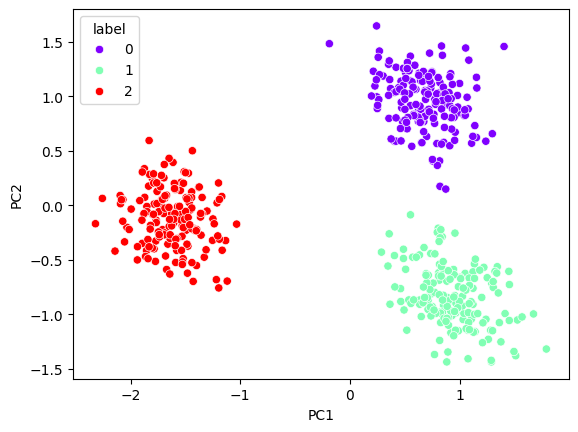

In [ ]:
sns.scatterplot(data=df_pca,x='PC1',y='PC2',hue='label',palette='rainbow')